# Predictive Models

### Data Prepping

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    confusion_matrix
)

df = pd.read_csv("europe_covid_cleaned.csv")

df['date'] = pd.to_datetime(df['date'])
df['year_month'] = df['date'].dt.to_period('M')

monthly_df = df.groupby(['location', 'year_month']).agg({
    'people_fully_vaccinated_per_hundred': 'mean',
    'new_cases_per_million': 'mean',
    'stringency_index': 'mean',
    'gdp_per_capita': 'mean',
    'new_deaths_per_million': 'mean'
}).reset_index()

threshold = monthly_df['new_deaths_per_million'].median()
monthly_df['high_mortality'] = (monthly_df['new_deaths_per_million'] > threshold).astype(int)

features = ['people_fully_vaccinated_per_hundred', 'new_cases_per_million', 'stringency_index', 'gdp_per_capita']
X = monthly_df[features].fillna(method='ffill')  
y = monthly_df['high_mortality']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Logistic Regression

In [32]:
logreg = LogisticRegression()
logreg.fit(X_train_scaled, y_train)
y_pred_logreg = logreg.predict(X_test_scaled)

## Random Forest

In [33]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

## SVM

In [34]:
svm_model = SVC()
svm_model.fit(X_train_scaled, y_train)
svm_preds = svm_model.predict(X_test_scaled)

## Naive Bayes

In [35]:
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
nb_preds = nb_model.predict(X_test)

## Evaluation


Model: Logistic Regression
Accuracy: 0.8294
Precision: 0.8959
Recall: 0.7586
F1-score: 0.8216
Confusion Matrix:
[[220  23]
 [ 63 198]]

Model: Random Forest
Accuracy: 0.8929
Precision: 0.8996
Recall: 0.8927
F1-score: 0.8962
Confusion Matrix:
[[217  26]
 [ 28 233]]

Model: SVM
Accuracy: 0.8393
Precision: 0.9091
Recall: 0.7663
F1-score: 0.8316
Confusion Matrix:
[[223  20]
 [ 61 200]]

Model: Naive Bayes
Accuracy: 0.7679
Precision: 0.9337
Recall: 0.5939
F1-score: 0.7260
Confusion Matrix:
[[232  11]
 [106 155]]


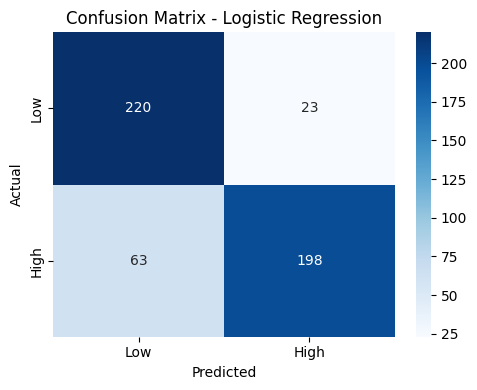

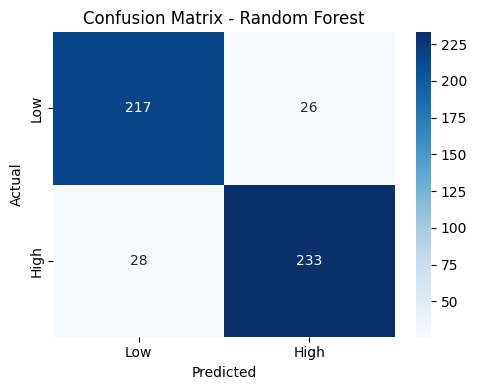

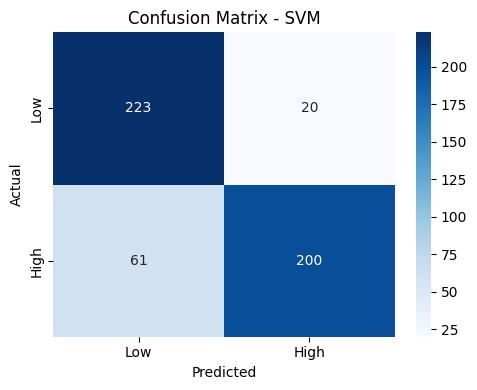

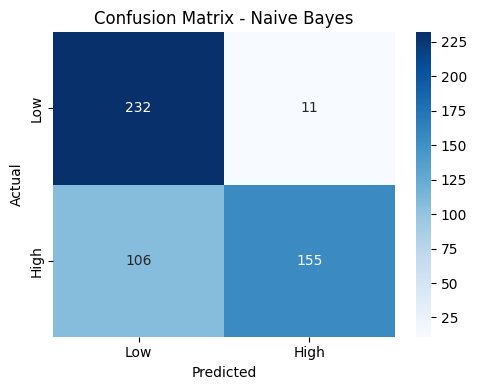

In [36]:
def evaluate_model(name, y_true, y_pred):
    print(f"\nModel: {name}")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall: {recall_score(y_true, y_pred):.4f}")
    print(f"F1-score: {f1_score(y_true, y_pred):.4f}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

evaluate_model("Logistic Regression", y_test, y_pred_logreg)
evaluate_model("Random Forest", y_test, y_pred_rf)
evaluate_model("SVM", y_test, svm_preds)
evaluate_model("Naive Bayes", y_test, nb_preds)

def plot_conf_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Low', 'High'],
                yticklabels=['Low', 'High'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix - {title}')
    plt.tight_layout()
    plt.show()

plot_conf_matrix(y_test, y_pred_logreg, "Logistic Regression")
plot_conf_matrix(y_test, y_pred_rf, "Random Forest")
plot_conf_matrix(y_test, svm_preds, "SVM")
plot_conf_matrix(y_test, nb_preds, "Naive Bayes")